Matías Lanas 22.466.806-6

Tarea 4 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(seed=48209)
#Importamos las librerias y definimos nuestro rng

In [3]:
#Constantes físicas necesarias para el desarrollo de los problemas
CteSigma_SB = 5.67e-8  #Constante de Stefan-Boltsman (W m^-2 K^-4)
RadioSolar = 6.957e8   #Radio Solar [m]
LuminosidadSolar = 3.828e26  #Luminosidad solar [W]
pc_a_m = 3.086e16    #Parsec a metros
#Como se ve, dejamos todas las constantes en valores iguales (W, m, etc.)

Parte I

In [6]:
N_estrellas = 100 #Tamaño de muestra

#Generamos las propiedades físicas con distribuiciones uniformes
radios_Rsol = rng.uniform(0.5, 5.0, size=N_estrellas)
distancias_pc = rng.uniform(50.0, 500.0, size=N_estrellas)
temperaturas_K = rng.uniform(3000.0, 10000.0, size=N_estrellas)

#Creamos el DataFrame de pandas
df_catalogo = pd.DataFrame({
    'ID': [f'Estrella{i+1:03d}' for i in range(N_estrellas)],
    'Radio Solar': radios_Rsol,
    'Distancia en parsec': distancias_pc,
    'Temperatura efectiva': temperaturas_K
})

#Mostrar las primeras 10 filas del catálogo
print('--- Primeras 10 filas del catálogo ---')
print(df_catalogo.head(10))

#Estadísticas descriptivas del catálogo inicial
print('\n--- Estadísticas descriptivas ---')
print(df_catalogo.describe())

--- Primeras 10 filas del catálogo ---
            ID  Radio Solar  Distancia en parsec  Temperatura efectiva
0  Estrella001     3.542002           422.825490           7497.407692
1  Estrella002     2.995895           182.605779           7927.243197
2  Estrella003     1.103802           260.626150           9970.792887
3  Estrella004     1.952459           139.921384           4820.749329
4  Estrella005     3.912041           475.254405           3783.811291
5  Estrella006     4.150895           252.194437           3858.525720
6  Estrella007     2.531535           163.620400           3751.963029
7  Estrella008     1.684100           470.422356           9689.850873
8  Estrella009     4.063150           207.363800           3578.139685
9  Estrella010     1.456773           231.665318           7242.887883

--- Estadísticas descriptivas ---
       Radio Solar  Distancia en parsec  Temperatura efectiva
count   100.000000           100.000000            100.000000
mean      2.611894   

Parte II

In [14]:
#Conversión de unidades para las fórmulas
Radios_m = df_catalogo['Radio Solar'] * RadioSolar
Distancias_m = df_catalogo['Distancia en parsec'] * pc_a_m

# a) Calcular la luminosidad mediante la ley de Stefan-Boltzmann (en Watts)
Luminosidad_watts = 4*np.pi* (Radios_m ** 2) * CteSigma_SB * (df_catalogo['Temperatura efectiva'] ** 4)

# b) Calculo de flujo observado en W m^-2
Flujo_en_Wm2 = Luminosidad_watts / (4 * np.pi * (Distancias_m ** 2))

# c) Agregamos ambos calculos a nuestro DataFrame
df_catalogo['Luminosidad_Lsol'] = Luminosidad_watts / LuminosidadSolar
df_catalogo['Flujo_Wm2'] = Flujo_en_Wm2

# d) Estrellas con mayor y menos luminosidad y flujo
estrella_max_L = df_catalogo.loc[df_catalogo['Luminosidad_Lsol'].idxmax()]
estrella_min_L = df_catalogo.loc[df_catalogo['Luminosidad_Lsol'].idxmin()]
estrela_max_F = df_catalogo.loc[df_catalogo['Flujo_Wm2'].idxmax()]
estrela_min_F = df_catalogo.loc[df_catalogo['Flujo_Wm2'].idxmin()]

print('\n--- Extremos de luminosidad y flujo ---')
print(f'Máxima luminosidad: {estrella_max_L['ID']} con {estrella_max_L['Luminosidad_Lsol']}')
print(f'Mínima luminosidad: {estrella_min_L['ID']} con {estrella_min_L['Luminosidad_Lsol']}')
print(f'Máximo flujo observado: {estrela_max_F['ID']} con {estrela_max_F['Flujo_Wm2']} W m^-2')
print(f'Mínimoo flujo observado: {estrela_min_F['ID']} con {estrela_min_F['Flujo_Wm2']} W m^-2')


--- Extremos de luminosidad y flujo ---
Máxima luminosidad: Estrella087 con 136.1863415257675
Mínima luminosidad: Estrella059 con 0.06971855916332882
Máximo flujo observado: Estrella058 con 2.6984258755328963e-10 W m^-2
Mínimoo flujo observado: Estrella069 con 1.1842424298399564e-14 W m^-2


Parte III

In [38]:
Flujo_limite = 2e-10 #Límite de detección del telescopio dado por la tarea

# a) Clasificación de cada estrella
df_catalogo['Clasificacion'] = np.where(df_catalogo['Flujo_Wm2'] >= Flujo_limite, 'Detectada', 'No detectada')

# b) Conteo por cada categoría
conteo = df_catalogo['Clasificacion'].value_counts()
print('\n--- Conteo de clasificación ---')
print(conteo)

# c) Porcentaje de estrella detectadas
Porcentaje_de_estrellas = (conteo.get('Detectada', 0) / N_estrellas) * 100
print(f'\nPorcentaje de estrellas de estrellas detectadas: {Porcentaje_de_estrellas:.1f}%')

# d) Promedios por categoría (flujo, distancia, temperatura)
promedios_categoria = df_catalogo.groupby('Clasificacion')[['Flujo_Wm2', 'Distancia en parsec', 'Temperatura efectiva']].mean()
#Usamos el comando groupby para sacar los promedios de manera mas eficiente
print('\n--- Promedios por categoría ---')
print(promedios_categoria)


--- Conteo de clasificación ---
Clasificacion
No detectada    99
Detectada        1
Name: count, dtype: int64

Porcentaje de estrellas de estrellas detectadas: 1.0%

--- Promedios por categoría ---
                  Flujo_Wm2  Distancia en parsec  Temperatura efectiva
Clasificacion                                                         
Detectada      2.698426e-10            51.546586           6345.076259
No detectada   1.614433e-11           287.045873           6546.386311


Parte IV

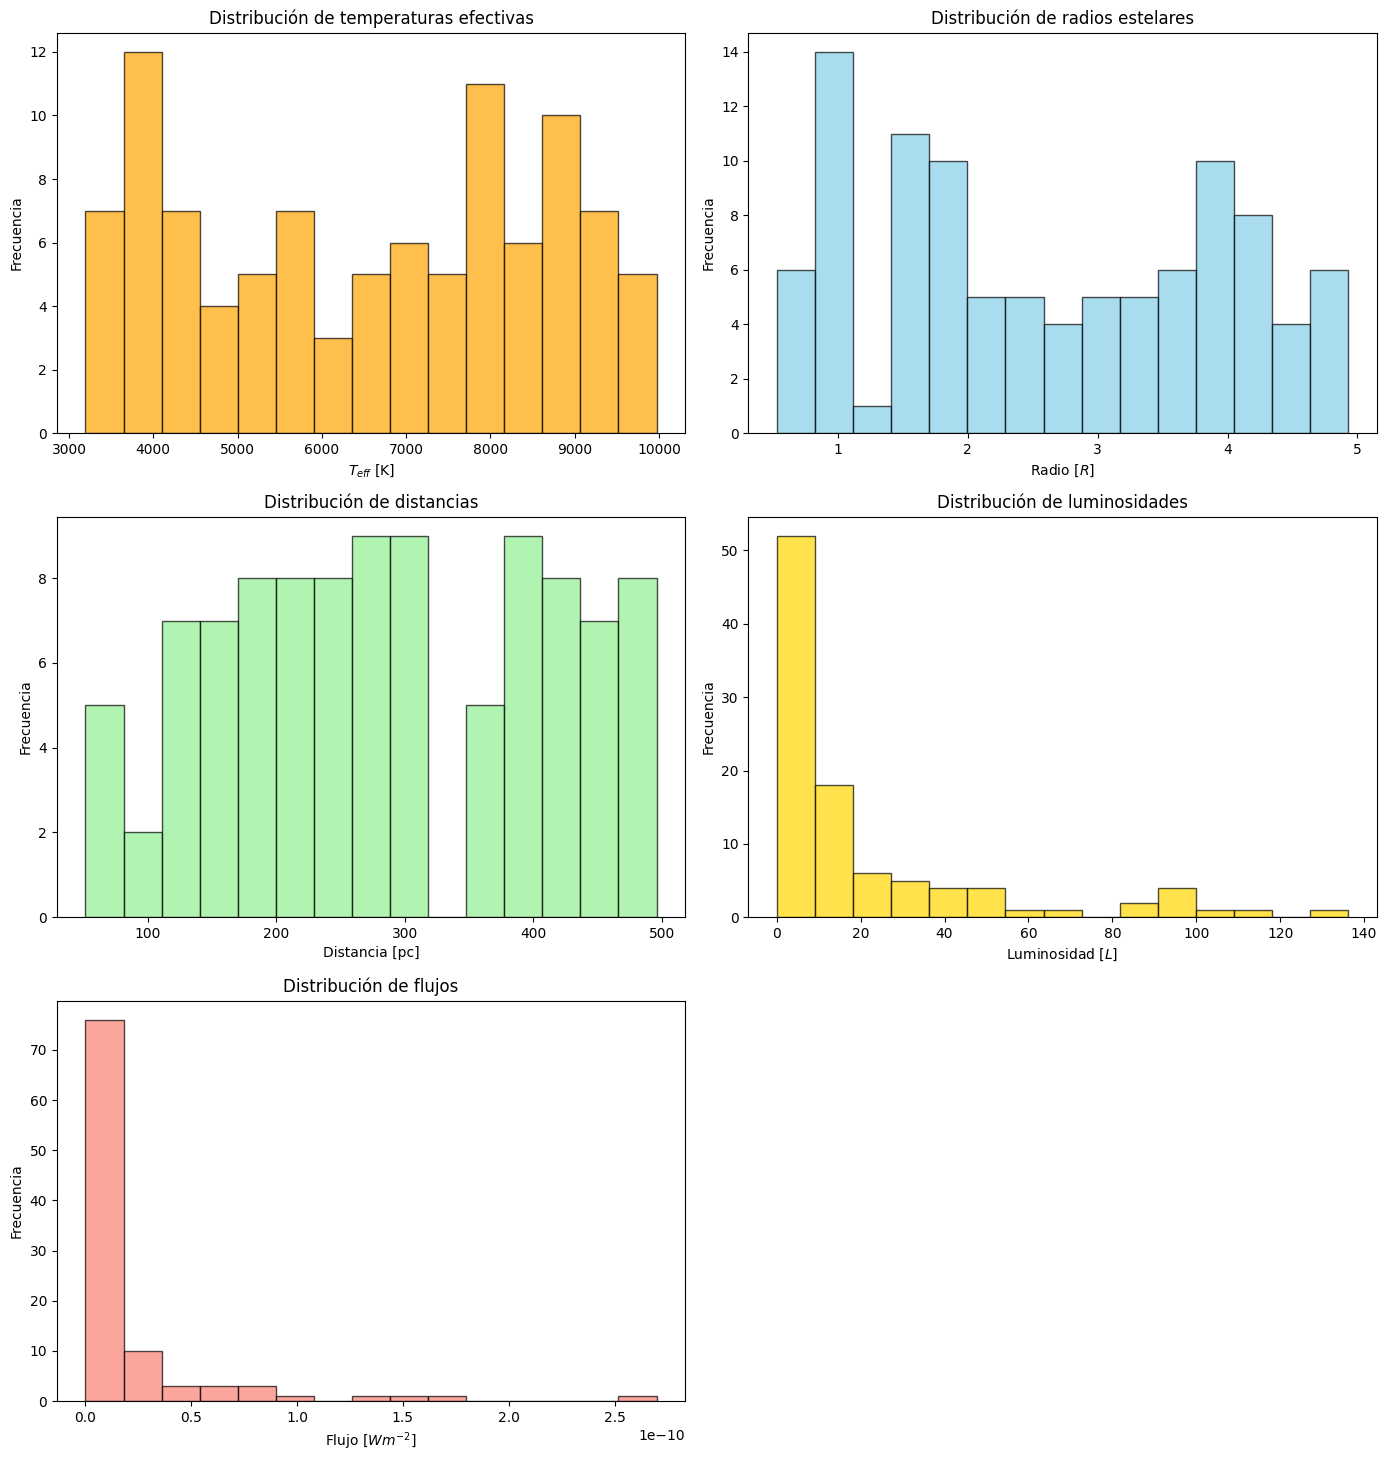

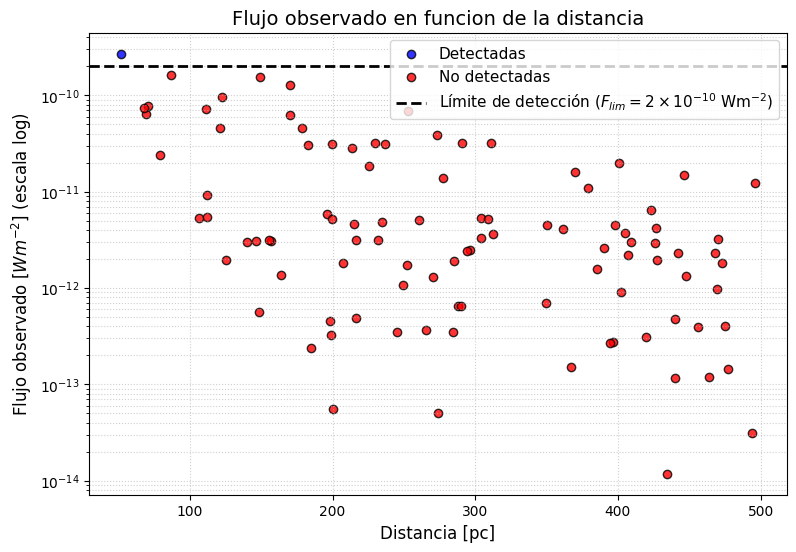

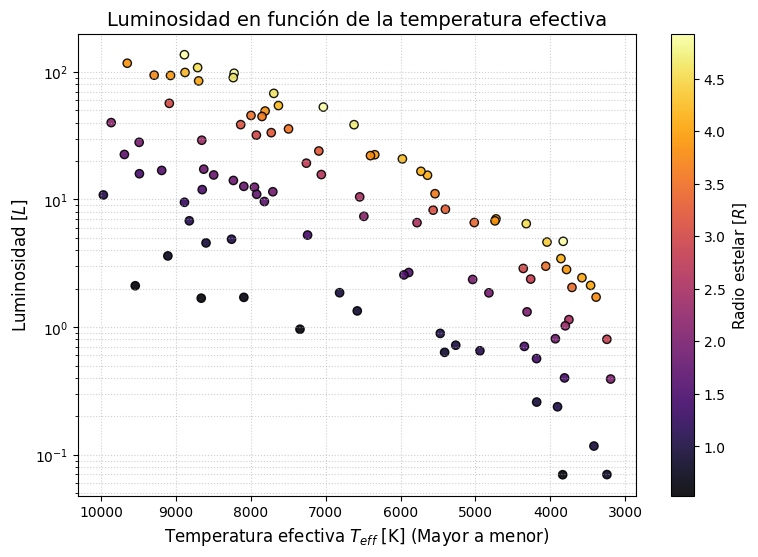

In [ ]:
#Preparamos los histogramas de distribuciones (a, b, c, d, e)
fig, axes = plt.subplots(3, 2, figsize=(14, 16))

# a) Histograma de temperaturas efectivas
axes[0, 0].hist(df_catalogo['Temperatura efectiva'], bins=15, color='orange', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Distribución de temperaturas efectivas')
axes[0, 0].set_xlabel('$T_{eff}$ [K]')
axes[0, 0].set_ylabel('Frecuencia')

# b) Histograma de radios
axes[0, 1].hist(df_catalogo['Radio Solar'], bins=15, color='skyblue', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Distribución de radios estelares')
axes[0, 1].set_xlabel('Radio [$R$]')
axes[0, 1].set_ylabel('Frecuencia')

# c) Histograma de distancia
axes[1, 0].hist(df_catalogo['Distancia en parsec'], bins=15, color='lightgreen', edgecolor='black', alpha=0.7)
axes[1, 0].set_title('Distribución de distancias')
axes[1, 0].set_xlabel('Distancia [pc]')
axes[1, 0].set_ylabel('Frecuencia')

# d) Histograma de luminosidades
axes[1, 1].hist(df_catalogo['Luminosidad_Lsol'], bins=15, color='gold', edgecolor='black', alpha=0.7)
axes[1, 1].set_title('Distribución de luminosidades')
axes[1, 1].set_xlabel('Luminosidad [$L$]')
axes[1, 1].set_ylabel('Frecuencia')

# e) Histograma de flujos
axes[2, 0].hist(df_catalogo['Flujo_Wm2'], bins=15, color='salmon', edgecolor='black', alpha=0.7)
axes[2, 0].set_title('Distribución de flujos')
axes[2, 0].set_xlabel('Flujo [$W m^{-2}$]')
axes[2, 0].set_ylabel('Frecuencia')

#Ocultamos el panel sobrante que no incorpora histograma
axes[2, 1].axis('off')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

#Ahora vamos con los gráficos más complejos (f, g)
# f) Gráfico de dispersión: flujo vs distancia

plt.figure(figsize=(9, 6))

detectadas = df_catalogo[df_catalogo['Clasificacion'] == 'Detectada']
no_detectadas = df_catalogo[df_catalogo['Clasificacion'] == 'No detectada']

#Puntos para cada categoría
plt.scatter(detectadas['Distancia en parsec'], detectadas['Flujo_Wm2'], color='blue', label='Detectadas', alpha=0.8, edgecolors='k')
plt.scatter(no_detectadas['Distancia en parsec'], no_detectadas['Flujo_Wm2'], color='red', label='No detectadas', alpha=0.8, edgecolors='k')

#Línea horizontal del limite de detección
plt.axhline(Flujo_limite, color='black', linestyle='--', linewidth=2, label=f'Límite de detección ($F_{{lim}} = 2\\times 10^{{-10}}$ Wm$^{{-2}}$)')
plt.yscale('log') #Se define la función como logarítmica
plt.xlabel('Distancia [pc]', fontsize=12)
plt.ylabel('Flujo observado [$W m^{-2}$] (escala log)', fontsize=12)
plt.title('Flujo observado en funcion de la distancia', fontsize=14)
plt.legend(fontsize=11)
plt.grid(True, which='both', ls=':', alpha=0.6)
plt.show()

# g) Grafico de luminosidad vs temperatura efectiva
plt.figure(figsize=(9,6))

plt.scatter(df_catalogo['Temperatura efectiva'], df_catalogo['Luminosidad_Lsol'], c=df_catalogo['Radio Solar'], cmap='inferno', edgecolors='k', alpha=0.9)
cbar = plt.colorbar()
cbar.set_label('Radio estelar [$R$]', fontsize=11)

plt.yscale('log') #definimos la funcion como logarítmica
plt.gca().invert_xaxis() #invertimos el eje para que vaya de mayor a menor

plt.xlabel('Temperatura efectiva $T_{eff}$ [K] (Mayor a menor)', fontsize=12)
plt.ylabel('Luminosidad [$L$]', fontsize=12)
plt.title('Luminosidad en función de la temperatura efectiva', fontsize=14)
plt.grid(True, which='both', ls=':', alpha=0.6)
plt.show()